<p align="center">
  <span style="font-size:32px"><b>ISEL</b></span><br>
  <span style="font-size:26px"><b>Departamento de Engenharia Informática</b></span><br>
  <span style="font-size:24px"><b>Licenciatura em Engenharia Informática e Multimédia</b></span><br>
  <span style="font-size:22px"><b>Processamento de Imagem e Visão</b></span><br><br>
  <span style="font-size:20px"><b>Trabalho Prático 1</b></span><br>
  <span style="font-size:16px">Semestre de Inverno 2026/2027</span><br><br>
  <span style="font-size:16px">Docente: Prof. Pedro Jorge</span><br>
  <span style="font-size:16px">Data: Novembro 2026</span><br><br>
  <span style="font-size:18px"><b>Trabalho realizado por:</b></span><br>
  <span style="font-size:16px">Beatriz Jesus nº52749</span><br>
  <span style="font-size:16px">Diana Oliveira nº52651</span><br>
</p>

<span style="font-size:19px"><b>Bibliotecas</b></span>

<span style="font-size:16px">Importações de Bibliotecas necessárias para a Implementação do Trabalho:<br></span>

<ul style="font-size:16px">
  <li><b>OpenCV</b> (<code>cv2</code>): Utilizada para processamento de imagens, visualização gráfica de sinais no domínio do tempo e análise visual.</li>
  <li><b>NumPy</b> (<code>numpy</code>): Utilizada para operações numéricas.</li>
  <li><b>Matplotlib</b> (<code>matplotlib.pyplot</code>): Utilizada para Visualização Grafica de Sinais no Domínio do Tempo e apoio à análise dos resultados.</li>

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [3]:

numTeste = [12, 21, 30, 32]
numTreino = [1, 2, 4, 9, 10, 11, 13, 22, 23, 25]
imagens= [1, 2, 4, 9, 10, 11, 12, 13, 21, 22, 23, 25, 30, 32]

teste = [cv2.imread(f"treino/lego{n}.jpg") for n in numTeste]
treino = [cv2.imread(f"treino/lego0{n}.jpg" if n < 10 else f"treino/lego{n}.jpg") for n in numTreino]
imagensTodas = [cv2.imread(f"treino/lego0{n}.jpg" if n < 10 else f"treino/lego{n}.jpg") for n in imagens]


IMAGEM = teste

INDEX_IMG = 4 # Imagem a treinar/testar


### Binarização


A Binarização consiste em converter a imagem numa imagem de apenas dois valores, em que as peças ficam a branco (255) e o fundo a preto (0). É o primeiro passo, pois separa o que interessa (as peças) do que não interessa (a mesa), permitindo depois etiquetar e medir cada objeto.
 
Em tons de cinzento, o fundo azul e algumas peças (vermelha, verde, laranja...) ficam com brilho parecido, e nenhum limiar, fixo ou Otsu, consegue distingui-los. Por isso, recorreu-se à cor. O fundo é azul, logo tem o canal B muito superior aos canais R e G. Nas peças isso não acontece: nas vermelhas e laranja domina o R, nas verdes o G, nas amarelas o R e o G, e nas brancas, bege ou cinzentas os três canais têm valores semelhantes. Assim, qualquer peça difere do fundo em pelo menos um canal.

O método tem três passos:

1. **Cor do fundo.** Para cada canal calculou-se um histograma (`cv2.calcHist`) e escolheu-se o valor mais frequente (`np.argmax`), o valor com mais píxels associados. Como o fundo ocupa a maior parte da imagem, a combinação dos três picos dá uma boa estimativa da sua cor. (O OpenCV guarda as imagens na ordem BGR.)
2. **Intervalos.** Em torno de cada pico definiu-se o intervalo [pico − tolerância, pico + tolerância], com uma tolerância própria para cada canal (B: 115, G: 73, R: 32). Usou-se `np.clip` para manter os limites entre 0 e 255.
3. **Segmentação.** O `cv2.inRange` marca como fundo os píxeis que têm os três canais dentro dos respetivos intervalos. O resultado é invertido (`255 - fundo`), pelo que tudo o que fica fora de qualquer intervalo é considerado peça e fica a branco.


A tolerância existe porque o fundo não tem uma cor uniforme: varia com a iluminação e com as sombras projetadas pelas peças, que também têm de ser classificadas como fundo. Uma sombra reduz os três canais, aproximadamente na mesma proporção, pelo que a descida em valor absoluto é maior no canal com valor mais alto. Como o fundo é azul, é o B que mais varia, e por isso precisa da tolerância mais alta (115). O G tem uma tolerância intermédia (73) e o R, que no fundo tem valores baixos e quase não varia, a mais baixa (32). Manter a tolerância do R pequena é também vantajoso porque é nesse canal que o fundo mais se distingue da maioria das peças (vermelhas, laranja, amarelas, brancas...), o que evita que sejam absorvidas pelo fundo. Os valores finais foram ajustados experimentalmente com as imagens de treino. 


Esta abordagem tem limitações:

- **Peças com cor próxima da do fundo.** Como os intervalos de tolerância são largos (sobretudo no canal B), uma peça azul, ou com uma cor próxima do azul do fundo, pode ter os três canais dentro dos intervalos e ser confundida com fundo, desaparecendo da binarização.
- **Sombras muito fortes.** Uma sombra que baixe os canais mais do que a tolerância permite fica fora dos intervalos e é segmentada como se fosse uma peça, o que cria regiões que não correspondem a nenhum objeto real.
- **Faces laterais das peças.** As peças têm altura e, devido à perspetiva da câmara, as suas faces laterais são visíveis, sobretudo nas peças mais afastadas do centro da imagem. Como a cor dessas faces também difere da do fundo, são segmentadas como parte da peça. A região binarizada fica assim maior num dos lados e deixa de ser um retângulo, o que altera a razão e a retangularidade medidas e pode levar à rejeição da peça na classificação.
- **Dependência das condições de captura.** Os valores de tolerância foram ajustados às imagens de treino, pelo que uma alteração da iluminação ou da cor do fundo exigiria recalculá-los.




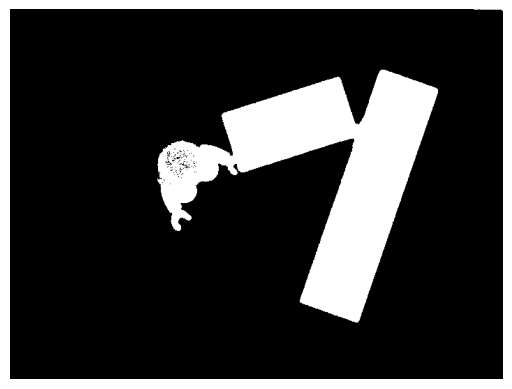

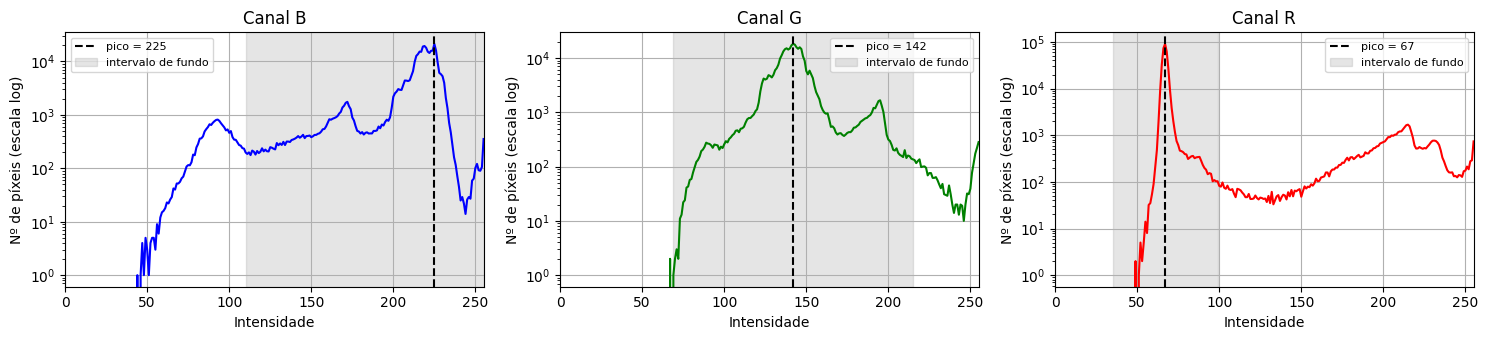

Canal B: pico = 225, tolerância = 115, intervalo = [110, 255]
Canal G: pico = 142, tolerância = 73, intervalo = [69, 215]
Canal R: pico = 67, tolerância = 32, intervalo = [35, 99]


In [4]:
# Binarização


histogramas = [] # lista de listas com 3 histogramas (para cada canal)
cores_fundo = []        # pico [b, g, r] de cada imagem = cor estimada do fundo
TOLS = [115, 73, 32]    # tolerâncias B, G, R

def pecas(img):

    cor = []
    hists = []
    # cor dominante = bin mais cheio do histograma 

    # loop em que se vai ao canal 0,1 e 2 (rgb) e calcula-se um histograma para cada um dos canais 
    for i in range(3):
        hist = cv2.calcHist([img], [i], None, [256], [0, 256])
        cor.append(np.argmax(hist)) # da o valor do canal que tem mais pixeis associados 
        hists.append(hist)
    histogramas.append(hists)
    cores_fundo.append(cor)

    # os tres canais juntos formam a cor mais dominante, que corresponde ao fundo
    b, g, r = cor
    tol_b, tol_g, tol_r = 115, 73, 32 
    
    # tolerâncias aplicadas
    lim_inf = np.clip([b - tol_b, g - tol_g, r - tol_r], 0, 255)
    lim_sup = np.clip([b + tol_b, g + tol_g, r + tol_r], 0, 255)
    fundo = cv2.inRange(img, lim_inf, lim_sup)

    return 255 - fundo



# para relatorio
def mostraHist(hists, cor=None, tols=None):
    cores = ["blue", "green", "red"]
    nomes = ["B", "G", "R"]

    fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
    for i in range(3):
        ax[i].plot(hists[i], color=cores[i])
        ax[i].set_yscale("log")
        ax[i].set_xlim(0, 255)
        ax[i].set_xticks(range(0, 256, 50))   # menos marcas, sem sobreposição
        ax[i].grid(True)
        ax[i].set_title("Canal " + nomes[i])
        ax[i].set_xlabel("Intensidade")
        ax[i].set_ylabel("Nº de píxeis (escala log)")

        # marca o pico e o intervalo de tolerância
        if cor is not None and tols is not None:
            ax[i].axvline(cor[i], color="black", linestyle="--", label=f"pico = {cor[i]}")
            ax[i].axvspan(max(cor[i] - tols[i], 0), min(cor[i] + tols[i], 255),
                          color="gray", alpha=0.2, label="intervalo de fundo")
            ax[i].legend(fontsize=8)

    plt.tight_layout() # evita que títulos e legendas se sobreponham
    plt.show()



binarizacao = [pecas(img) for img in imagensTodas]

# mostrar 1 para relatorio
plt.imshow(binarizacao[INDEX_IMG],cmap="gray")
plt.axis("off")
plt.show()

# index = 0
# for img in binarizacao:
#     cv2.imwrite(f'binarizacao/bin{index+1}.png', img)
#     index += 1

mostraHist(histogramas[INDEX_IMG], cor=cores_fundo[INDEX_IMG], tols=TOLS)

for nome, p, t in zip(["B", "G", "R"], cores_fundo[INDEX_IMG], TOLS):
    print(f"Canal {nome}: pico = {p}, tolerância = {t}, intervalo = [{max(p-t, 0)}, {min(p+t, 255)}]")


Os histogramas dos três canais permitem validar a escolha dos valores de tolerância utilizados na segmentação do fundo.

Como o fundo é a região que ocupa mais píxeis na imagem, o valor mais frequente de cada canal, isto é, o pico do histograma, corresponde à cor do fundo: B ≈ 225, G ≈ 142 e R ≈ 67. A escala logarítmica do eixo vertical permite observar em simultâneo este pico dominante e as populações minoritárias, que correspondem aos objetos.

A tolerância de cada canal define o intervalo de intensidades em torno do pico que é classificado como fundo (zona cinzenta na figura). A análise dos histogramas mostra que cada intervalo é adequado, pois abrange o pico e a sua dispersão natural e termina nos vales da curva, que separam o fundo das restantes populações (objetos). Esta análise é feita de seguida, para cada canal. 


- **Canal B:** O histograma apresenta um pico dominante em torno de 225. O intervalo [110, 255] estende-se desde o pico até ao vale em torno de 110, que separa o pico do fundo do máximo secundário, centrado em cerca de 90, associado aos objetos. Escolher o limite inferior neste vale garante que o intervalo abrange as variações da cor do fundo, sem incluir os objetos. O pequeno máximo local em cerca de 170 fica dentro do intervalo, pelo que é tratado como variação do fundo e não como objeto. Este é o canal com a distribuição mais larga (tolerância de 115, contra 73 em G e 32 em R), pelo que precisou de uma tolerância maior. O limite superior (225 + 115 = 340) ultrapassa 255 e é cortado por `np.clip`, por isso só o limite inferior (110) separa efetivamente o fundo das peças neste canal.


- **Canal G:** O histograma apresenta um pico dominante em torno de 142 e uma distribuição larga à volta dele. O intervalo [69, 215] acompanha essa distribuição: o limite inferior (69) coincide com o início da distribuição, pois abaixo deste valor praticamente não há píxeis, e o limite superior (215) situa-se depois do máximo local em cerca de 195, onde o número de píxels começa a descer. O máximo, em cerca de 195, é considerado variação do fundo e não como objeto local, por isso, fica dentro do intervalo. Este é o canal com distribuição de largura intermédia (tolerância de 73, contra 115 em B e 32 em R). Neste canal, ao contrário do B, não existe um vale bem definido que separe o fundo dos objetos e ambos os limites são efetivos, pois ficam dentro de [0, 255].


- **Canal R:** O histograma apresenta um pico dominante em torno de 67, muito estreito, o que indica que o fundo tem valores muito homogéneos neste canal. Por isso, o intervalo [35, 99] é o mais estreito dos três. O limite superior (99) situa-se onde a curva, depois do pico, desce. Os valores acima de 100 pertencem aos objetos, com máximos locais em cerca de 215 e 230 (variações da cor dos objetos) e, por isso, ficam fora do intervalo. O limite inferior (35) está abaixo do menor valor com píxeis (cerca de 48), pelo que não tem efeito prático, e só o limite superior (99) separa efetivamente o fundo das peças neste canal.


### Operadores Morfológicos

Depois da binarização, as imagens ainda tinham defeitos que prejudicariam a extração dos contornos, como pequenas manchas brancas de ruído no fundo e buracos pretos no interior das peças, causados sobretudo pelos reflexos nos pinos do Lego. Como as peças estão a branco e o fundo a preto, usaram-se dois operadores morfológicos:

- **Fecho** (dilatação → erosão): preenche os buracos pretos menores do que o elemento estruturante, como os reflexos nos pinos.
- **Abertura** (erosão → dilatação): remove os objetos brancos menores do que o elemento estruturante, ou seja, o ruído. A erosão elimina-os e a dilatação seguinte repõe o tamanho das regiões que sobreviveram.

Ambos usam um **elemento estruturante**, uma pequena matriz binária que percorre a imagem e define a vizinhança de cada píxel considerada na operação. A sua forma e o seu tamanho determinam o efeito final.

**Forma:** Escolheu-se a elipse (`cv2.MORPH_ELLIPSE`). A cruz foi descartada porque deixava vários pontos brancos isolados onde não existiam peças, ou seja, não eliminava bem o ruído. O retângulo foi descartado porque as peças não estão alinhadas com os eixos da imagem, por isso os cantos iam desaparecendo e as peças ficavam arredondadas. Este formato só seria adequado se todas as peças estivessem direitas. Assim, escolheu-se a elipse, uma vez que não deformou as peças nem acrescentou ruído.

**Tamanho:** Na abertura usou-se (14, 14), porque com tamanhos menores, algumas manchas de ruído sobreviviam à erosão e, ao serem dilatadas a seguir, mantinham-se na imagem. No fecho usou-se (9, 9), porque com tamanhos menores, a dilatação não era suficiente para tapar todos os buracos pretos e, como a erosão seguinte só repunha o contorno exterior e esses buracos permaneciam na imagem final. O fecho usou um elemento menor do que o da abertura, porque os buracos a tapar são pequenos, e um elemento maior arriscava unir peças vizinhas.

**Ordem dos Operadores** Aplica-se primeiro o fecho e só depois a abertura, porque cada operador atua sobre uma coisa diferente. Se a abertura fosse primeiro, na peça com buracos, o branco entre esses buracos ia-se reduzir a tiras estreitas, mais finas do que o elemento estruturante. A erosão apagá-las-ia por completo, os buracos cresceriam até se fundirem entre si e com o fundo, e a dilatação não recupera o que foi apagado, ficando um "esqueleto" da peça. Com o fecho primeiro, os buracos são tapados e a peça chega à abertura como uma região sólida, muito mais larga do que o elemento estruturante, sobrevivendo intacta. A abertura limita-se então ao que se pretende, que é eliminar o ruído pequeno fora das peças.

(np.float64(-0.5), np.float64(705.5), np.float64(529.5), np.float64(-0.5))

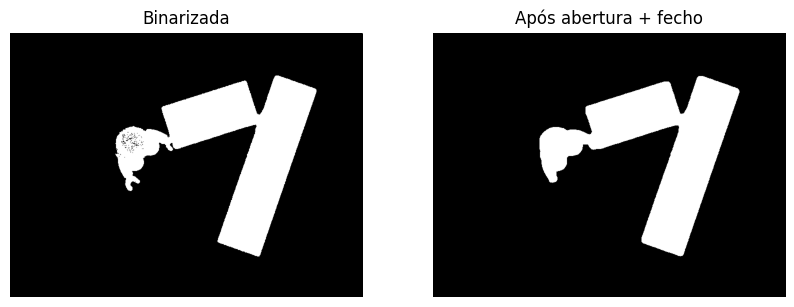

In [15]:
# Operadores Morfológicos

kernel_a = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (14,14)) # elemento estruturante da abertura
kernel_f= cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)) # do fecho


# O fecho é melhor 

# A função limpar aplica abertura seguida de fecho a uma imagem binária
# Problema: não separam peças muito próximas
def limpar(bin_):

    fecho = cv2.morphologyEx(bin_, cv2.MORPH_CLOSE, kernel_f)   # fecho, tapa buracos pretos até 15px
    abertura = cv2.morphologyEx(fecho, cv2.MORPH_OPEN, kernel_a)    # abertura, apaga qq coisa branca mais estreita que 22px

    return abertura


img_limpo = [limpar(b) for b in binarizacao]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(binarizacao[INDEX_IMG], cmap="gray")
ax[0].set_title("Binarizada")
ax[0].axis("off")

ax[1].imshow(img_limpo[INDEX_IMG], cmap="gray")
ax[1].set_title("Após abertura + fecho")
ax[1].axis("off")

# index = 0
# for img in img_limpo:
#     cv2.imwrite(f'limpo/limpo{index+1}.png', img)
#     index += 1

Utilizou-se uma erosão com elemento estruturante elíptico de 15×15 (raio 7 px), repetida 4 vezes. A erosão elimina estruturas mais estreitas do que o elemento, e as zonas de contacto entre peças são mais finas do que as próprias peças, pelo que desaparecem e as peças ficam em componentes ligados distintos. Com 4 iterações removem-se 28 px por lado, o que desfaz os contactos observados e preserva ~36 px na dimensão mais curta da menor peça (~92 px). O elemento elíptico é isotrópico, pelo que a perda de píxeis é a mesma em todas as direções e independente da orientação da peça, o que permite compensá-la com uma margem constante (56 px) nas medições.

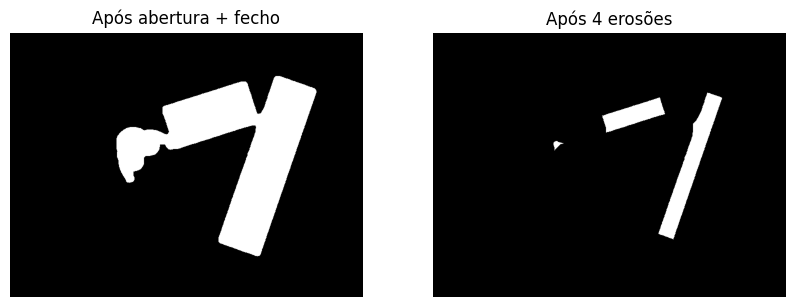

Imagem limpa:  1
Imagem com peças separadas:  3


In [16]:
# Separar peças juntas com Erosão

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15,15))

# A função separar aplica erosão a uma imagem limpa para separar as peças
def separar(limpa, it=4):
    return cv2.erode(limpa, kernel, iterations=it) 


img_sep   = [separar(l) for l in img_limpo]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(img_limpo[INDEX_IMG], cmap="gray")
ax[0].set_title("Após abertura + fecho")
ax[0].axis("off")

ax[1].imshow(img_sep[INDEX_IMG], cmap="gray")
ax[1].set_title("Após 4 erosões")
ax[1].axis("off")
plt.show()


# para guardar as imgs
# index = 0
# for img in img_sep:
#     cv2.imwrite(f'separada/sep{index+1}.png', img)
#     index += 1


# ===== Testar a partir da etiquetação =====

resultado_limpo = [cv2.connectedComponents(tl) for tl in img_limpo] # lista de tuplos: (número de objetos, etiquetas)
resultado_sep= [cv2.connectedComponents(ts) for ts in img_sep] 
# [x][0] -> n objetos
# [x][1] -> etiquetas

print("Imagem limpa: ", resultado_limpo[INDEX_IMG][0] - 1) # 0 é o fundo, daí subtraí-se 1
print("Imagem com peças separadas: ", resultado_sep[INDEX_IMG][0] - 1) 

### Etiquetação

A etiquetação consiste em atribuir uma etiqueta única (identificador) a cada objeto da imagem binarizada, ou seja, a cada conjunto de píxeis brancos ligados entre si, designado por componente conexa. Assim, cada peça passa a ser identificada e tratada individualmente, o que permite distingui-las umas das outras nas fases seguintes.

Para a etiquetação utilizaram-se as funções `cv2.findContours`, que determina o contorno de cada objeto, e `cv2.drawContours`, que desenha esses contornos sobre a imagem, permitindo verificar visualmente se a deteção está correta. Cada contorno detetado corresponde a um objeto e fica identificado pelo seu índice na lista devolvida, que funciona como etiqueta.

Optou-se por não utilizar `cv2.connectedComponents`, porque esta função devolve apenas uma imagem em que cada região tem uma etiqueta numérica, sem fornecer o contorno. No entanto, o contorno é indispensável para calcular as medidas de cada objeto, que servem de base à classificação das peças.

Número de objetos encontrados:  3


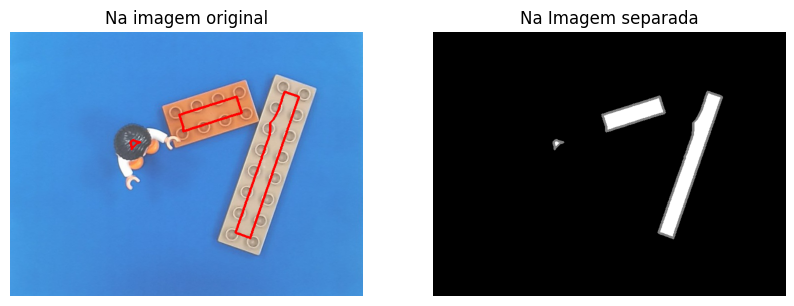

In [7]:
# Etiquetação

# findContours -> devolve uma lista de pontos da fronteira, e cada contorno corresponde a um objeto.
# drawContours desenha esses contornos, ou preenche-os se thickness=-1, o que dá uma máscara por peça.
# Os contornos servem depois para o próximo passo

contornos = [cv2.findContours(ts, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0] for ts in img_sep]
# RETR_EXTERNAL apanha só os contornos exteriores
# CHAIN_APPROX_SIMPLE guarda só os pontos finais de cada linha (poupa memória)
# [0] -> só para obter os contornos pq a função devolve um tuplo mas só precisamos do primeiro elemento


contorno = contornos[INDEX_IMG]
print("Número de objetos encontrados: ", len(contorno)) 

org = imagensTodas[INDEX_IMG].copy()
cv2.drawContours(org, contorno, -1, (0, 0, 255), 3)

sep = img_sep[INDEX_IMG].copy()
cv2.drawContours(sep, contorno, -1, 128, 3) # contornos a cinzento

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(org[:, :, ::-1])
ax[0].set_title("Na imagem original")
ax[0].axis("off")

ax[1].imshow(sep, cmap="gray")
ax[1].set_title("Na Imagem separada")
ax[1].axis("off")
plt.show()

Na imagem original, os contornos aparecem mais pequenos do que as peças, uma vez que as erosões aplicadas reduziram as dimensões dos objetos. Apesar disso, observa-se que cada contorno se encontra totalmente contido na peça correspondente e que nenhum contorno toca noutro. Isto confirma que a erosão separou corretamente as peças que estavam em contacto, e o número de objetos detetados coincide com o número real de peças.

### Extração de Características

A extração de características consiste em calcular, para cada objeto etiquetado, um conjunto de medidas que o descrevam e permitam classificá-lo (2x2, 2x4, 2x6 ou 2x8) e rejeitar os objetos que não são peças retangulares. Esta fase é mais complexa porque as peças surgem em posições e orientações diferentes e, por vezes, como estavam em contacto, aparecem com um rasto da ligação anterior. Por isso, as medidas variam de imagem para imagem e não existe um valor único para cada classe.

A função `cv2.minAreaRect` calcula o retângulo de área mínima que contém o contorno, mesmo quando este se encontra rodado. Foi escolhida porque as suas dimensões não dependem da orientação da peça, ao contrário do `cv2.boundingRect`, que devolve um retângulo alinhado com os eixos da imagem. As peças são retângulos cuja razão entre o lado maior e o lado menor toma os valores teóricos 1, 2, 3 e 4, correspondentes a 2x2 (2/2), 2x4 (4/2), 2x6 (6/2) e 2x8 (8/2). Esta razão é, por isso, a medida principal de classificação.

Já a função `cv2.contourArea` calcula a área, em píxeis, da região delimitada pelo contorno, isto é, a área da peça e não a do retângulo. É proporcional ao número de pinos (4, 8, 12 e 16) e, como a câmara está fixa e paralela à mesa, a escala é constante.

Combinando as duas funções obtém-se a retangularidade, definida por:

`retangularidade = área do contorno / área do retângulo mínimo`

Numa peça retangular perfeita as duas áreas coincidem e o valor é 1. Numa peça com outra forma, o contorno preenche apenas parte do retângulo e o valor desce. Esta medida permite rejeitar as outras peças de Lego presentes na imagem, que apresentam valores inferiores aos das peças retangulares.

Como as erosões reduziram os contornos, as dimensões medidas são inferiores às reais, pelo que é necessário compensar esta perda. Cada iteração da erosão retira a cada lado do objeto um número de píxeis igual ao raio do elemento estruturante. Este é uma elipse de 15x15 píxeis, logo o raio é 7 (7 + 1 do centro + 7 = 15). Com 4 iterações perdem-se 4 × 7 = 28 px em cada lado. Como cada dimensão (largura ou comprimento) tem dois lados opostos, a perda total por dimensão é:

`margem = n.º de erosões × raio × 2 = 4 × 7 × 2 = 56 px`

Este valor é somado à largura e ao comprimento medidos.

A compensação é necessária porque a erosão retira um número fixo de píxeis a cada dimensão e não uma percentagem. Assim, a razão entre os lados altera-se e deixa de tomar os valores 1, 2, 3 e 4, o que invalidaria as referências usadas na classificação.

Criou-se função medir() que recebe um contorno e devolve as suas métricas. A retangularidade é calculada antes da compensação, porque a área do contorno é a da peça erodida e, por isso, a área do retângulo com que é comparada também tem de o ser. Se a margem fosse somada primeiro, compararia uma área reduzida com um retângulo já “reposto” e a retangularidade ficaria errada.

Depois de compensadas as dimensões, é necessário ordená-las, porque o `cv2.minAreaRect` pode devolver w como o lado curto ou como o lado comprido, consoante a rotação da peça. Com max e min, o valor maior corresponde sempre ao lado comprido e o menor ao lado curto. Assim, a razão maior / menor é sempre ≥ 1 e não depende da orientação.

In [8]:
# Extração de Características

margem = 4 * 7 * 2 # número de erosões * raio do elemento estruturante * lados 

# função que recebe um contorno e devolve as suas medidas num dicionário
def medir(contorno):
    
    (cx, cy), (w, h), _ = cv2.minAreaRect(contorno)
    # (cx, cy): o centro do retângulo
    # (w, h): a largura e a altura desse retângulo

    area = cv2.contourArea(contorno) 

    ret = area / (w * h) # retangularidade

    w += margem # (*AQUI)
    h += margem # (*AQUI)

    maior, menor = max(w, h), min(w, h)

    return {"centro": (cx, cy), "maior": maior, "menor": menor,
            "razao": maior / menor, "area": area, "retangularidade": ret}

A função `numerar()` é uma função auxiliar que percorre os objetos detetados numa imagem, atribui um número a cada um e recolhe as respetivas métricas calculadas através da função medir(). Foi criada para reunir, para todas as imagens de treino, os valores medidos de cada objeto, de modo a compará-los com a classe real a que pertencem. Desta comparação resulta o intervalo de valores típico de cada classe (2x2, 2x4, 2x6 e 2x8), a partir do qual se definem os limiares usados na classificação.

--- lego1 ---
#0 | razão 1.00 | área 1709 | ret 0.93
#1 | razão 1.57 | área 6680 | ret 0.75
#2 | razão 2.00 | área 4474 | ret 0.95
#3 | razão 1.52 | área 3250 | ret 0.95
#4 | razão 2.01 | área 4168 | ret 0.96
#5 | razão 1.97 | área 4629 | ret 0.94
#6 | razão 3.94 | área 9733 | ret 0.95
#7 | razão 1.05 | área 1895 | ret 0.92
#8 | razão 1.04 | área 1592 | ret 0.95


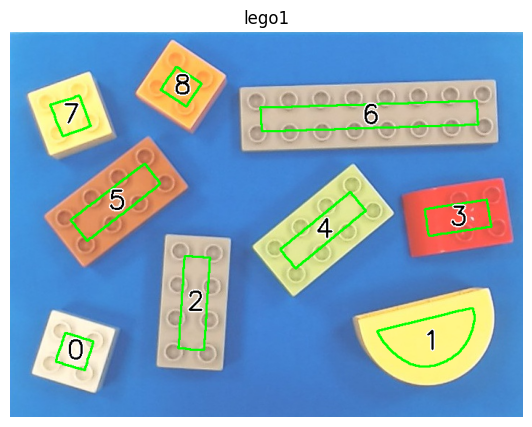

--- lego2 ---
#0 | razão 1.94 | área 4604 | ret 0.94
#1 | razão 1.28 | área 1858 | ret 0.88
#2 | razão 2.06 | área 4449 | ret 0.93
#3 | razão 3.98 | área 9388 | ret 0.95
#4 | razão 1.03 | área 1787 | ret 0.94
#5 | razão 1.04 | área 1562 | ret 0.95


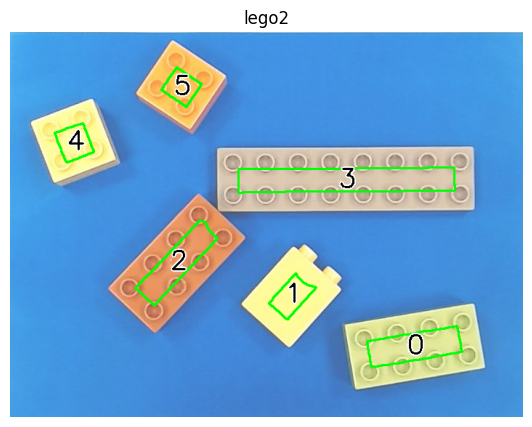

--- lego4 ---
#0 | razão 1.02 | área 1289 | ret 0.94
#1 | razão 1.99 | área 4303 | ret 0.97
#2 | razão 1.02 | área 1423 | ret 0.93


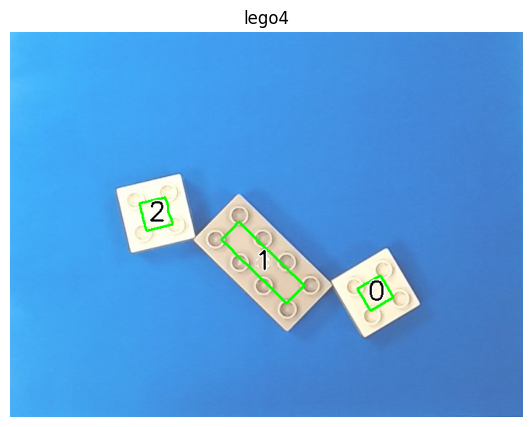

--- lego9 ---
#0 | razão 1.99 | área 4372 | ret 0.96
#1 | razão 1.92 | área 4189 | ret 0.86
#2 | razão 2.93 | área 8310 | ret 0.97
#3 | razão 3.94 | área 9784 | ret 0.96


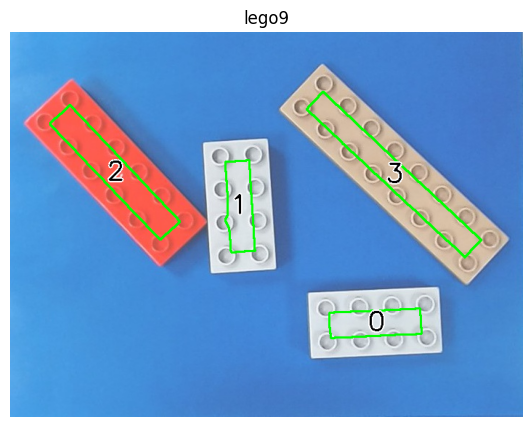

--- lego10 ---
#0 | razão 1.13 | área 137 | ret 0.47
#1 | razão 1.97 | área 4052 | ret 0.94
#2 | razão 3.79 | área 9281 | ret 0.82


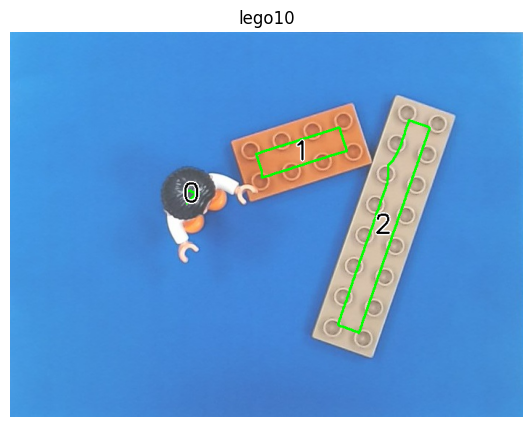

--- lego11 ---
#0 | razão 1.93 | área 4890 | ret 0.96
#1 | razão 3.65 | área 10314 | ret 0.81
#2 | razão 1.96 | área 4228 | ret 0.96


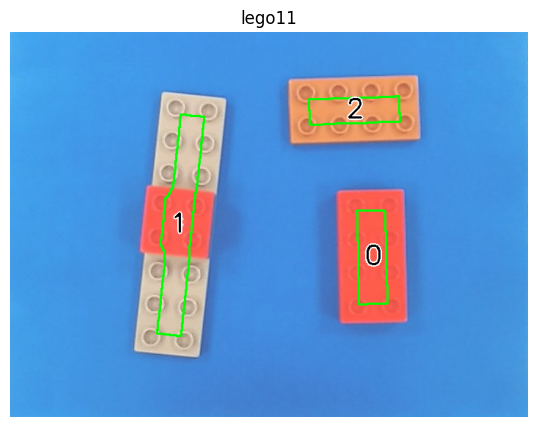

--- lego13 ---
#0 | razão 1.97 | área 4312 | ret 0.96
#1 | razão 2.01 | área 4069 | ret 0.96
#2 | razão 2.79 | área 9350 | ret 0.95
#3 | razão 1.53 | área 6036 | ret 0.72


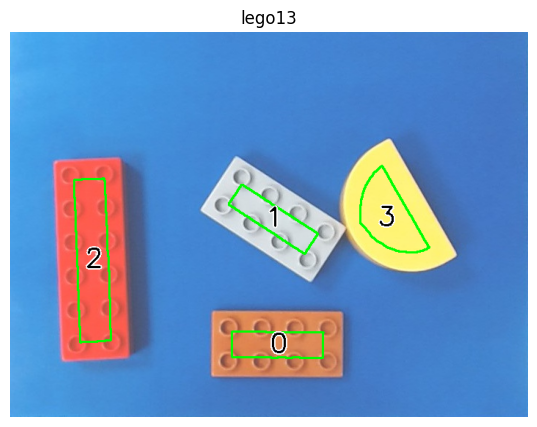

--- lego22 ---
#0 | razão 1.00 | área 1278 | ret 0.95
#1 | razão 1.01 | área 1368 | ret 0.99
#2 | razão 1.00 | área 1512 | ret 0.99
#3 | razão 1.02 | área 1334 | ret 0.94


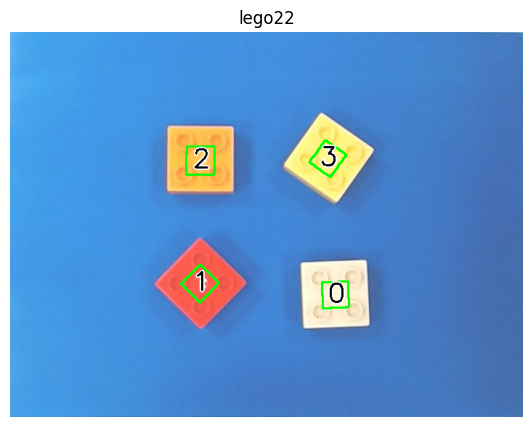

--- lego23 ---
#0 | razão 1.97 | área 4503 | ret 0.96
#1 | razão 1.96 | área 4504 | ret 0.96
#2 | razão 1.93 | área 4690 | ret 0.98
#3 | razão 1.93 | área 4968 | ret 0.95


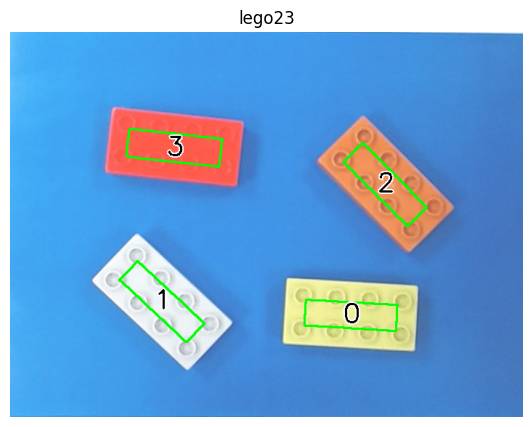

--- lego25 ---
#0 | razão 3.95 | área 9953 | ret 0.96


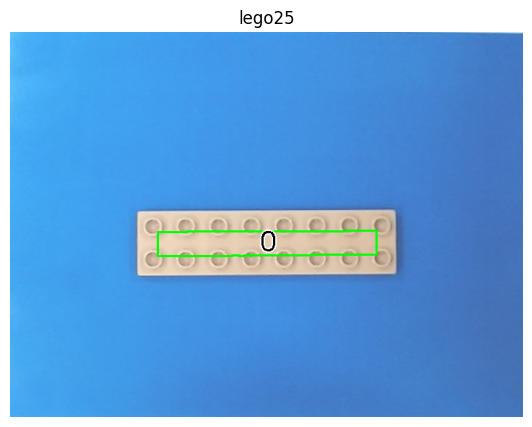

In [9]:
def numerar(n):
    i = imagens.index(n)
    vis = imagensTodas[i].copy()
    print(f"--- lego{n} ---")
    for k, c in enumerate(contornos[i]):        
        m = medir(c)
        cx, cy = int(m["centro"][0]), int(m["centro"][1])
        cv2.drawContours(vis, [c], -1, (0, 255, 0), 2)
        cv2.putText(vis, str(k), (cx - 10, cy + 10), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 6)  # contorno branco
        cv2.putText(vis, str(k), (cx - 10, cy + 10), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 0), 2)        # número
        print(f"#{k} | razão {m['razao']:.2f} | área {m['area']:.0f} | ret {m['retangularidade']:.2f}")
    plt.figure(figsize=(7, 5))
    plt.imshow(vis[:, :, ::-1])
    plt.title(f"lego{n}")
    plt.axis("off")
    plt.show()

for n in numTreino:
    numerar(n)

Percorreram-se todas as imagens para extrair os valores relevantes e preencher as listas abaixo.

In [10]:
razoes = {"2x2": [1.00, 1.05, 1.04, 1.03, 1.04, 1.02, 1.02, 1.00, 1.01, 1.00, 1.02], 
          "2x4": [2.00, 2.01, 1.97, 1.94, 2.06, 1.99, 1.99, 1.92, 1.97, 1.93, 1.96, 1.97, 2.01, 1.97, 1.96, 1.93, 1.93], 
          "2x6": [ 2.93, 2.79], 
          "2x8": [3.94, 3.98, 3.94, 3.79, 3.65, 3.95]}

# retangularidade de todas as peças reais
rets   = [0.93, 0.95, 0.95, 0.96, 0.94, 0.95, 0.92, 0.95, 0.94, 0.93, 0.95, 0.94, 0.95, 0.94, 0.97, 0.93, 0.96, 0.86, 0.97,
          0.96, 0.94, 0.82, 0.96, 0.81, 0.96, 0.96, 0.96, 0.95, 0.95, 0.99, 0.99, 0.94, 0.96, 0.96, 0.98, 0.95, 0.96]   

lixo   = {"razao": [1.57, 1.28, 1.13, 1.53], 
          "ret": [0.75, 0.88, 0.47, 0.72]}

print("Ret min = ", min(rets))
for classe, v in razoes.items():
    print(f"{classe}: min = {min(v):.2f}, max = {max(v):.2f}")

Ret min =  0.81
2x2: min = 1.00, max = 1.05
2x4: min = 1.92, max = 2.06
2x6: min = 2.79, max = 2.93
2x8: min = 3.65, max = 3.98


A retangularidade mínima observada nas peças reais foi de 0,81, pelo que este valor foi usado como limiar inferior para aceitar um objeto como peça retangular.

Para cada tipo de peça determinou-se, a partir das imagens de treino, o intervalo de valores da razão (entre o mínimo e o máximo medidos), apresentado acima. No entanto, estes intervalos são justos demais, porque refletem apenas as imagens de treino, e é necessário dar-lhes uma folga para que a classificação funcione noutras imagens. Ao executar o algoritmo com as imagens de teste, verificou-se que algumas peças ficavam fora dos intervalos, e foi-se determinando quanto era necessário alargá-los.

Concluiu-se que a folga não podia ser um valor único para todas as classes. Se se subtraísse e somasse a mesma margem a todos os intervalos, esta teria de ser pelo menos 0,11 para que uma peça 2x6 de teste fosse aceite. Porém, com essa margem, o limite superior do 2x2 passaria de 1,05 para 1,16, e um objeto que não é uma peça, com razão 1,13 (imagem lego10), passaria a ser contado como 2x2.

Optou-se, por isso, por começar com uma margem de 0,04 em cada extremo do intervalo (mínimo − 0,04 e máximo + 0,04) e depois ajustar a folga de cada classe individualmente, acrescentando mais 0,04. Este alargamento foi particularmente importante no 2x6, porque as imagens de treino só continham duas peças desta classe. Com tão poucas amostras, os valores mínimo e máximo medidos representam mal a variação real, pelo que o intervalo obtido é demasiado estreito.

### Classificação

A classificação é a etapa final do trabalho e é nela que se avalia o desempenho do algoritmo. Consiste em atribuir cada objeto detetado a uma das classes (2x2, 2x4, 2x6 ou 2x8) com base nas métricas calculadas, ou em rejeitá-lo quando não corresponde a nenhuma peça retangular.

Para isso criou-se a função `classificar()`, que recebe as métricas de um objeto e compara-as com os intervalos definidos na secção anterior. O objeto é atribuído à classe cujo intervalo de razão contém o valor medido, desde que a retangularidade seja suficientemente elevada. Se nenhuma condição se verificar, o objeto é rejeitado, o que permite excluir as outras peças de Lego presentes na imagem.

Criou-se também a função `contar()`, que recebe os contornos de uma imagem e a imagem original correspondente. Esta função percorre os contornos e, para cada um, chama `medir()` para obter as métricas e `classificar()` para determinar a classe. No fim, conta quantas peças de cada classe estão presentes e escreve sobre a imagem original o texto com a classe atribuída, o que permite verificar visualmente o que foi identificado e como foi classificado.

Por fim, apresentam-se alguns resultados de treino e de teste, comparando o que foi obtido com a realidade.

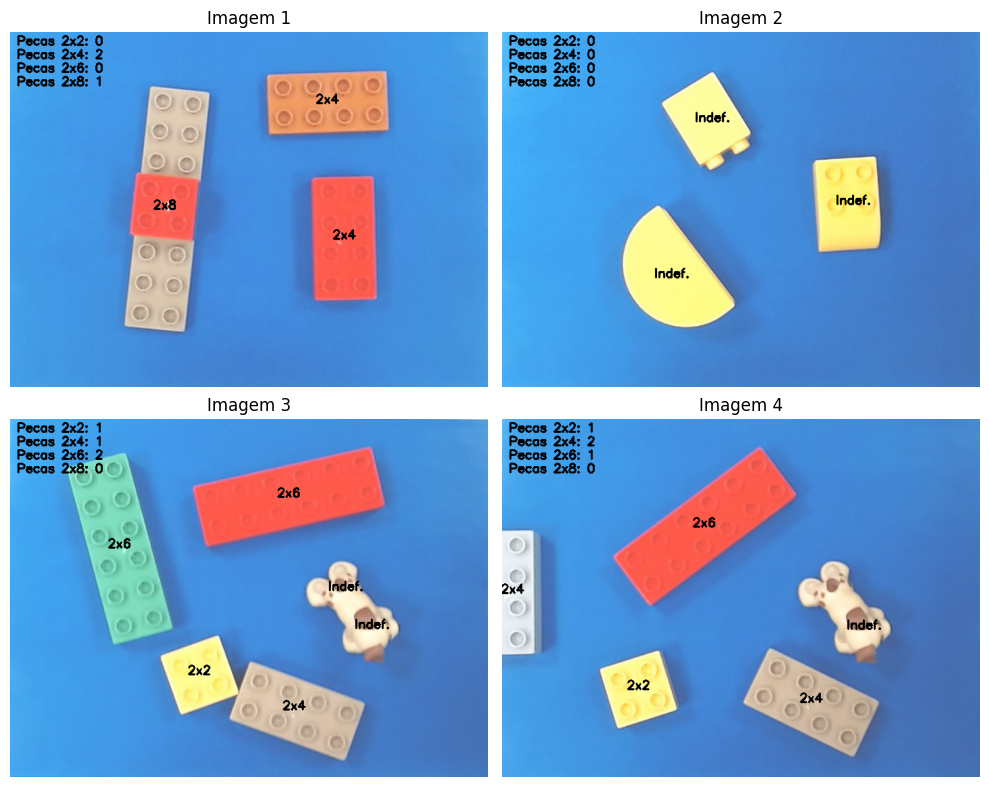

In [11]:
# Classificação

def classificar(m):
    # rejeitar o que não é retangular (semicírculo, outras peças, restos da erosão)
    if m["retangularidade"] < 0.80:
        return None
    r = m["razao"]
    # classificar pela razão, com zonas de rejeição entre as classes
    if 0.96 <= r <= 1.09: # + 0.04
        return "2x2"
    elif 1.84 <= r <= 2.14: # + 0.08
        return "2x4"
    elif 2.67 <= r <= 3.05: # + 0.12
        return "2x6"
    elif 3.49 <= r <= 4.14: # + 0.16
        return "2x8"
    return None   # razão fora das classes 


# Escreve na imagem as peças identificadas
def contar(conts, img_cor):
    contagem = {"2x2": 0, "2x4": 0, "2x6": 0, "2x8": 0}
    saida = img_cor.copy()

    for c in conts:
        m = medir(c) # métricas
        tipo = classificar(m) # classificação

        cx, cy = m["centro"]

        if tipo is None:
            cv2.putText(saida, "Indef.", (int(cx) - 17, int(cy)), # imagem, texto, posição
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2) # fonte, tamanho, cor, espessura
            continue

        contagem[tipo] += 1
        
        cv2.putText(saida, tipo, (int(cx) - 17, int(cy)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2) 

    # resumo no canto superior esquerdo
    for k, tipo in enumerate(["2x2", "2x4", "2x6", "2x8"]):
        cv2.putText(saida, f"Pecas {tipo}: {contagem[tipo]}", (10, 20 + 20 * k),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)
    return saida


img_clasf = [contar(contornos[k], imagensTodas[k]) for k in range(len(contornos))]
img_a_mostrar = [5,6,12,13]

fig, ax = plt.subplots(2, 2, figsize=(10, 8))
ax = ax.flatten()

for k, i in enumerate(img_a_mostrar):
    img = img_clasf[i]
    ax[k].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax[k].set_title(f"Imagem {k + 1}")
    ax[k].axis("off")

plt.tight_layout()
plt.show()

    
# salvar imagens 
# index = 0
# for img in img_clasf:
#     cv2.imwrite(f'classificado/clsf{index+1}.png', img)
#     index += 1

### Análise dos resultados

Os resultados da classificação foram os esperados. Para demonstrar o funcionamento do sistema e justificar alguns resultados, selecionaram-se quatro imagens representativas.

Na primeira imagem, o sistema identificou uma peça como sendo da classe 2x8. Como a imagem é binarizada, as peças perdem a cor, deixando de ser possível distingui-las com base nessa característica. Quando duas peças estão em contacto e a erosão não consegue separá-las, são detetadas como um único objeto. Neste caso, as dimensões obtidas são compatíveis com a classe 2x8. Embora o resultado seja coerente com a informação disponível, evidencia uma limitação do método, que se baseia apenas na forma dos objetos.

Na segunda imagem, três peças foram corretamente classificadas como indefinidas. Uma delas não apresenta um formato retangular, pelo que não cumpre o critério de retangularidade. Outra encontra-se deitada, apresentando uma razão entre dimensões que não corresponde a nenhuma das classes definidas, muito possivelmente porque os pinos ocupam uma área extra, alterando as proporções do objeto. Por fim, uma peça com aspeto semelhante ao de uma 2x2 apresenta uma curvatura que reduz a sua retangularidade, levando à sua rejeição. Estas decisões demonstram que o sistema consegue excluir objetos que não cumprem os critérios estabelecidos.

Na terceira imagem, todas as peças foram identificadas corretamente. No entanto, a indicação «indefinido» aparece duas vezes sobre uma das peças corretamente classificadas. Este comportamento resulta da aplicação de quatro erosões com um elemento estruturante de 15×15 píxeis, que podem deixar pequenos resíduos dos objetos. Estes resíduos originam contornos adicionais que não correspondem a nenhuma classe e são, por isso, rejeitados. Apesar de afetarem a representação visual, não alteram a contagem final das peças.

Na última imagem, o sistema classificou como 2x4 uma peça cortada pelo limite da imagem. Esta classificação é coerente com as características visíveis, uma vez que a peça apresenta um formato retangular, uma retangularidade superior ao limiar de 0,80 e uma razão entre dimensões compatível com a classe 2x4. Assim, apesar de estar parcialmente fora da imagem, o objeto reúne os critérios necessários para ser classificado.

--- lego32 ---
#0 | razão 1.98 | área 4435 | ret 0.96
#1 | razão 1.02 | área 1552 | ret 0.94
#2 | razão 1.01 | área 276 | ret 0.53
#3 | razão 2.14 | área 3736 | ret 0.97
#4 | razão 2.89 | área 8148 | ret 0.95


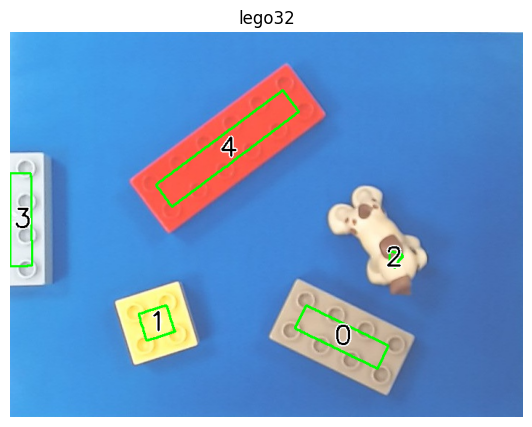

In [12]:
numerar(32)

Como é possível observar, a peça 3 sofreu menos erosão do que as restantes, uma vez que se encontra encostada à borda da imagem. Durante a operação, parte do elemento estruturante fica fora dos limites da imagem e por omissão, o `cv2.erode()` considera os píxeis exteriores como tendo o valor máximo (255), pelo que estes não interferem no processo de erosão. Consequentemente, o lado esquerdo da peça mantém a sua posição original, enquanto o lado direito, o topo e a base são erodidos normalmente.

Pelas métricas, a razão (2.14) fica no limite máximo da classe 2x4 e a retangularidade é próxima de 1. Como a parte visível é compatível com uma peça 2x4, não se pode afirmar que o sistema a classificou mal, mas a classificação pode ser pouco fiável, porque a peça completa pode ser maior.

### Conclusão

Concluindo, o sistema funcionou de forma correta e dentro do esperado nas imagens disponibilizadas, lidando bem com sombras, peças em contacto e objetos que não são peças retangulares. Todas as peças retangulares foram identificadas corretamente e os restantes objetos foram rejeitados. Apresenta, no entanto, algumas limitações: peças de cores diferentes em contacto podem ser detetadas como um único objeto (lego11), peças curtadas podem ser identificadas (lego32) e a erosão pode originar contornos residuais, rejeitados como “indefinido” (lego30), embora estes não afetem a contagem final.